# ¿Por qué se van los clientes de una empresa de telefonía e internet?
**Reto Final – Analítica de Negocios**

**Integrantes:** _[Laura Restrepo]_ · _[Santiago Negrete]_ · _[Carolina Tamayo]_

**Base de datos:** *Telco Customer Churn* (IBM), 7.043 clientes y 21 variables
- Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- Archivo CSV (el que usa este notebook): https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

**Modelos vistos en clase:** Naive Bayes, Árbol de decisión, Red neuronal y K-Means

**Contenido:** 1 Introducción · 2 Problema · 3 Objetivos · 4 Datos · 5 Modelos y métricas · 6 Resultados · 7 Discusión · 8 Limitaciones · 9 Ética · 10 Conclusiones · 11 Recomendaciones · 12 Bibliografía

## 1. Introducción

Casi todas las personas ya tienen plan de celular o internet. Por eso a una empresa de telefonía le conviene más **no perder a los clientes que ya tiene**. Cuando un cliente cancela (esto se llama *churn*), la empresa deja de recibir lo que ese cliente pagaba cada mes.

Escogimos la base *Telco Customer Churn* de IBM (está en Kaggle). Tiene datos de 7.043 clientes: qué servicios tienen, qué contrato, cómo pagan, cuántos meses llevan y cuánto pagan al mes. También dice si el cliente se fue o no.

Sirve para el reto porque tiene una **variable categórica** para clasificar y agrupar (`Churn`, y también `Contract`, `InternetService` y `PaymentMethod`) y una **variable numérica** para pronosticar (`MonthlyCharges`, lo que paga al mes).

## 2. Definición del problema

La empresa pierde casi 1 de cada 4 clientes (26,5 %) y no sabe bien a quién ni por qué. Entonces gasta plata en ofertas para todos, en vez de enfocarse en los que sí se van a ir.

**Preguntas:**
1. ¿Cómo son los clientes que cancelan?
2. ¿Se puede saber antes quién se va a ir?
3. ¿Cuánta plata al mes se pierde y en qué clientes?
4. ¿Cuánto debería pagar un cliente al mes según sus servicios?
5. ¿Hay grupos de clientes parecidos?

## 3. Objetivos

**General:** usar modelos de analítica para saber qué clientes tienen más riesgo de irse y ayudar a la empresa a decidir a quién ofrecerle algo para que se quede.

**Específicos**
- Describir la base de datos.
- Predecir la cancelación con Naive Bayes, Árbol de decisión y Red neuronal, y compararlos.
- Pronosticar el cobro mensual con un Árbol de decisión y una Red neuronal.
- Hacer grupos de clientes con K-Means.
- Dar recomendaciones claras.

## 4. Datos
### 4.1 Cargar los datos
Bajamos el archivo directo de GitHub (es la misma base de Kaggle). Si el link falla, el código deja subir el `.csv` a mano.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, KBinsDiscretizer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import CategoricalNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             mean_absolute_error, mean_squared_error, r2_score, silhouette_score)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
SEED = 42

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    from google.colab import files        # plan B: subir el archivo de Kaggle a mano
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0])

print("Filas, columnas:", df.shape)
df.head()

Filas, columnas: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 4.2 Qué tiene la base

| Variable | Tipo | Qué significa | Uso |
|---|---|---|---|
| `customerID` | Texto | Código del cliente | No se usa |
| `gender` | Categórica | Género | Clasificación (con cuidado, ver ética) |
| `SeniorCitizen` | 0/1 | Si es adulto mayor | Clasificación |
| `Partner`, `Dependents` | Categórica | Si tiene pareja / personas a cargo | Clasificación |
| `tenure` | Numérica | Meses como cliente (0 a 72) | Pronóstico y agrupamiento |
| `PhoneService`, `MultipleLines` | Categórica | Teléfono y varias líneas | Clasificación |
| `InternetService` | Categórica | DSL, fibra óptica o sin internet | Clasificación y agrupamiento |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Categórica | Servicios extra | Clasificación |
| `StreamingTV`, `StreamingMovies` | Categórica | TV y películas | Clasificación |
| `Contract` | Categórica | Mensual, 1 año o 2 años | Clasificación y agrupamiento |
| `PaperlessBilling` | Categórica | Factura electrónica | Clasificación |
| `PaymentMethod` | Categórica | Forma de pago | Clasificación |
| `MonthlyCharges` | Numérica | Lo que paga al mes (USD) | **Pronóstico** |
| `TotalCharges` | Numérica | Total pagado hasta hoy (USD) | Agrupamiento |
| `Churn` | Categórica | Si canceló (Yes/No) | **Variable a clasificar** |

In [ ]:
df.info()
print()
print(df.describe().round(2))
print()
print("Valores faltantes por columna (incluye celdas vacías de TotalCharges):")
print((df.replace(" ", np.nan).isna().sum()).loc[lambda s: s > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 4.3 Limpieza
- `TotalCharges` venía como texto porque 11 clientes tenían la celda vacía. Son clientes nuevos con 0 meses (todavía no les cobran), así que les pusimos 0.
- Quitamos `customerID` porque no sirve para predecir.
- Creamos `ChurnBin` (1 = se fue, 0 = se quedó) para sacar porcentajes más fácil.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print("Clientes con TotalCharges vacío y tenure == 0:", (df["TotalCharges"].isna() & (df["tenure"] == 0)).sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")
df["ChurnBin"] = (df["Churn"] == "Yes").astype(int)

print("Duplicados:", df.duplicated().sum())
print(f"Tasa de cancelación global: {df.ChurnBin.mean():.1%}")

Clientes con TotalCharges vacío y tenure == 0: 11
Duplicados: 22
Tasa de cancelación global: 26.5%


### 4.4 Exploración
Antes de usar los modelos, miramos cómo cambia la cancelación según algunas variables.

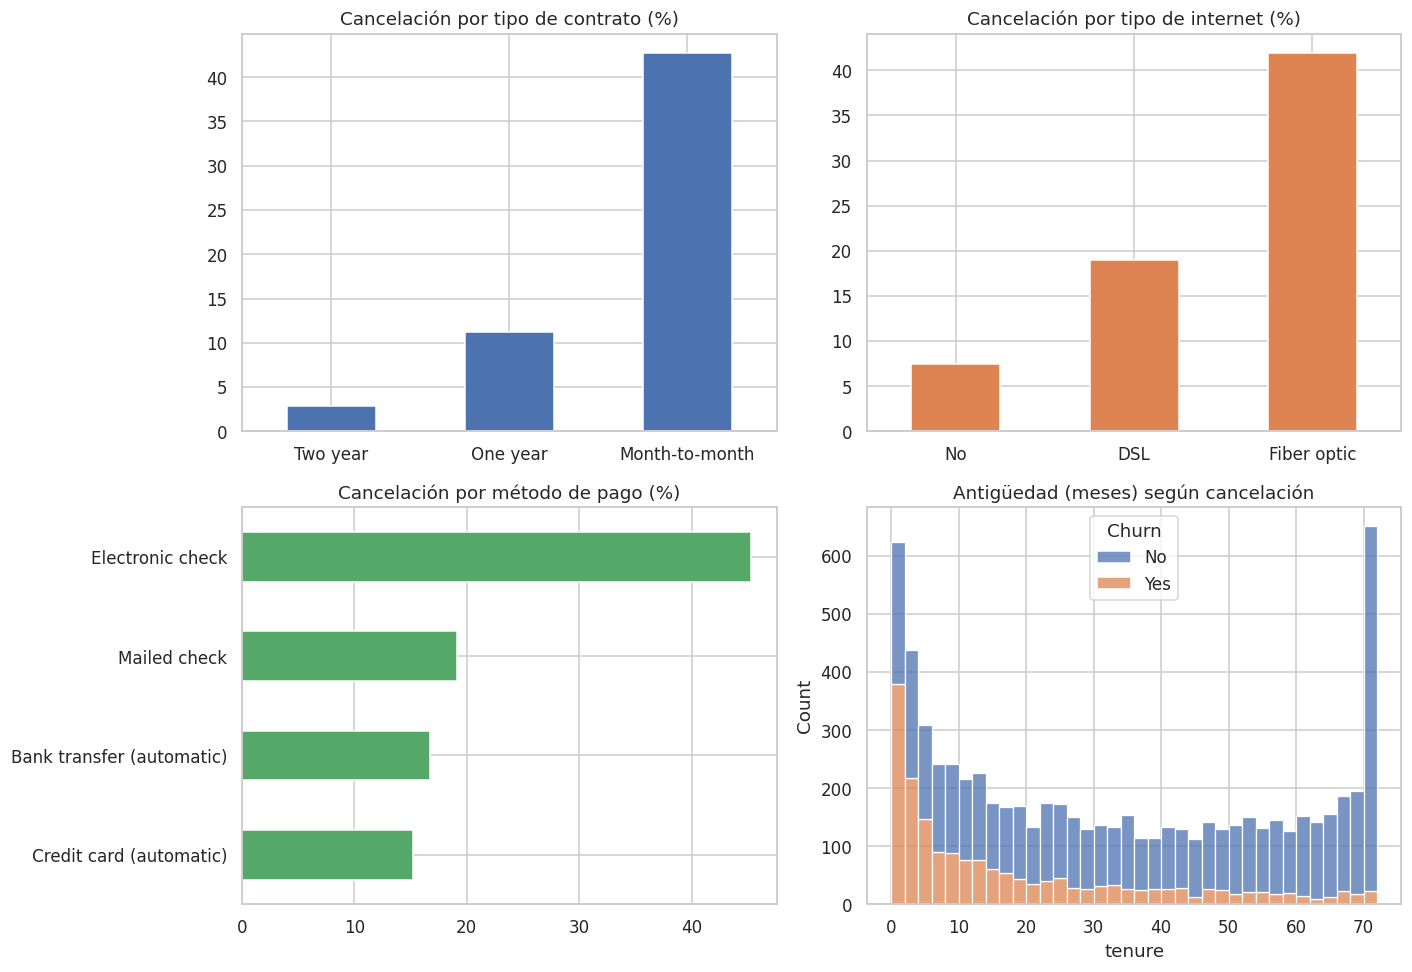

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

(df.groupby("Contract").ChurnBin.mean().sort_values() * 100).plot.bar(ax=ax[0,0], color="#4C72B0")
ax[0,0].set_title("Cancelación por tipo de contrato (%)"); ax[0,0].set_xlabel(""); ax[0,0].tick_params(axis="x", rotation=0)

(df.groupby("InternetService").ChurnBin.mean().sort_values() * 100).plot.bar(ax=ax[0,1], color="#DD8452")
ax[0,1].set_title("Cancelación por tipo de internet (%)"); ax[0,1].set_xlabel(""); ax[0,1].tick_params(axis="x", rotation=0)

(df.groupby("PaymentMethod").ChurnBin.mean().sort_values() * 100).plot.barh(ax=ax[1,0], color="#55A868")
ax[1,0].set_title("Cancelación por método de pago (%)"); ax[1,0].set_ylabel("")

sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=36, ax=ax[1,1])
ax[1,1].set_title("Antigüedad (meses) según cancelación")
plt.tight_layout(); plt.show()

In [ ]:
resumen = df.groupby("Contract").agg(clientes=("ChurnBin","size"),
                                     tasa_cancelacion=("ChurnBin","mean"),
                                     cobro_mensual_prom=("MonthlyCharges","mean")).round(3)
display(resumen)
print("Tasa de cancelación por antigüedad:")
print(df.groupby("tenure").ChurnBin.mean().loc[[1, 12, 24, 48, 72]].round(3))

,clientes,tasa_cancelacion,cobro_mensual_prom
Contract,,,
Month-to-month,3875,0.427,66.398
One year,1473,0.113,65.049
Two year,1695,0.028,60.770


Tasa de cancelación por antigüedad:
tenure
1     0.620
12    0.325
24    0.245
48    0.141
72    0.017
Name: ChurnBin, dtype: float64


**Lo que vimos:** con contrato mensual se va el 42,7 % de los clientes y con contrato de dos años solo el 2,8 %. Con fibra óptica cancela el 41,9 % y con DSL el 19,0 %. Los que pagan con cheque electrónico cancelan el 45,3 %. Además, el 62 % de los clientes con 1 mes de antigüedad se fue, y ese porcentaje baja mientras más tiempo llevan.

## 5. Modelos, método y métricas

**Paso a paso**
1. Dividimos los datos: 80 % para entrenar y 20 % para probar.
2. Preparamos las variables (las categóricas pasan a 0 y 1 y las numéricas se escalan).
3. Entrenamos los modelos y los probamos con datos que no habían visto. También hicimos validación cruzada de 5 partes.
4. Miramos qué variables pesan más y lo pasamos a plata.

**Modelos**
| Tarea | Modelos | Variable |
|---|---|---|
| Clasificación | Naive Bayes, Árbol de decisión, Red neuronal | `Churn` |
| Pronóstico | Árbol de decisión, Red neuronal | `MonthlyCharges` |
| Agrupamiento | K-Means | `tenure`, `MonthlyCharges`, `TotalCharges` |

**Métricas**
- *Clasificación:* exactitud, precisión, recall, F1 y AUC. Como solo el 27 % cancela, la exactitud sola no alcanza. Por eso miramos el **recall** (de los que se van, cuántos encontramos) y el **AUC**.
- *Pronóstico:* MAE (error promedio en dólares), RMSE y R².
- *Agrupamiento:* coeficiente de silueta y si los grupos sirven para el negocio.

## 6. Resultados
### 6.1 Clasificación de la cancelación: Naive Bayes, Árbol de decisión y Red neuronal

In [ ]:
X = df.drop(columns=["Churn", "ChurnBin"]); y = df["ChurnBin"]
cat = X.select_dtypes("object").columns.tolist()
num = [c for c in X.columns if c not in cat]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

# Para el árbol y la red: categóricas a 0/1 y numéricas escaladas
pre_general = ColumnTransformer([("c", OneHotEncoder(drop="first"), cat), ("n", StandardScaler(), num)])
# Para Naive Bayes: categóricas a números y las numéricas se dividen en 5 grupos
pre_nb = ColumnTransformer([("c", OrdinalEncoder(), cat),
                            ("n", KBinsDiscretizer(5, encode="ordinal", strategy="quantile"), num)])

pipes = {
    "Naive Bayes": Pipeline([("pre", pre_nb), ("m", CategoricalNB(min_categories=5))]),
    "Árbol de decisión": Pipeline([("pre", pre_general),
                                   ("m", DecisionTreeClassifier(max_depth=5, min_samples_leaf=30,
                                                                class_weight="balanced", random_state=SEED))]),
    "Red neuronal": Pipeline([("pre", pre_general),
                              ("m", MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True,
                                                  max_iter=500, random_state=SEED))]),
}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
filas = []
for nombre, p in pipes.items():
    p.fit(Xtr, ytr)
    pred, prob = p.predict(Xte), p.predict_proba(Xte)[:, 1]
    filas.append({"Modelo": nombre, "Exactitud": accuracy_score(yte, pred), "Precisión": precision_score(yte, pred),
                  "Recall": recall_score(yte, pred), "F1": f1_score(yte, pred),
                  "AUC (prueba)": roc_auc_score(yte, prob),
                  "AUC (validación cruzada)": cross_val_score(p, X, y, cv=skf, scoring="roc_auc").mean()})
resultados = pd.DataFrame(filas).set_index("Modelo").round(3)
resultados

,Exactitud,Precisión,Recall,F1,AUC (prueba),AUC (validación cruzada)
Modelo,,,,,,
Naive Bayes,0.726,0.490,0.805,0.609,0.817,0.823
Árbol de decisión,0.732,0.497,0.805,0.614,0.829,0.831
Red neuronal,0.797,0.643,0.529,0.581,0.843,0.840


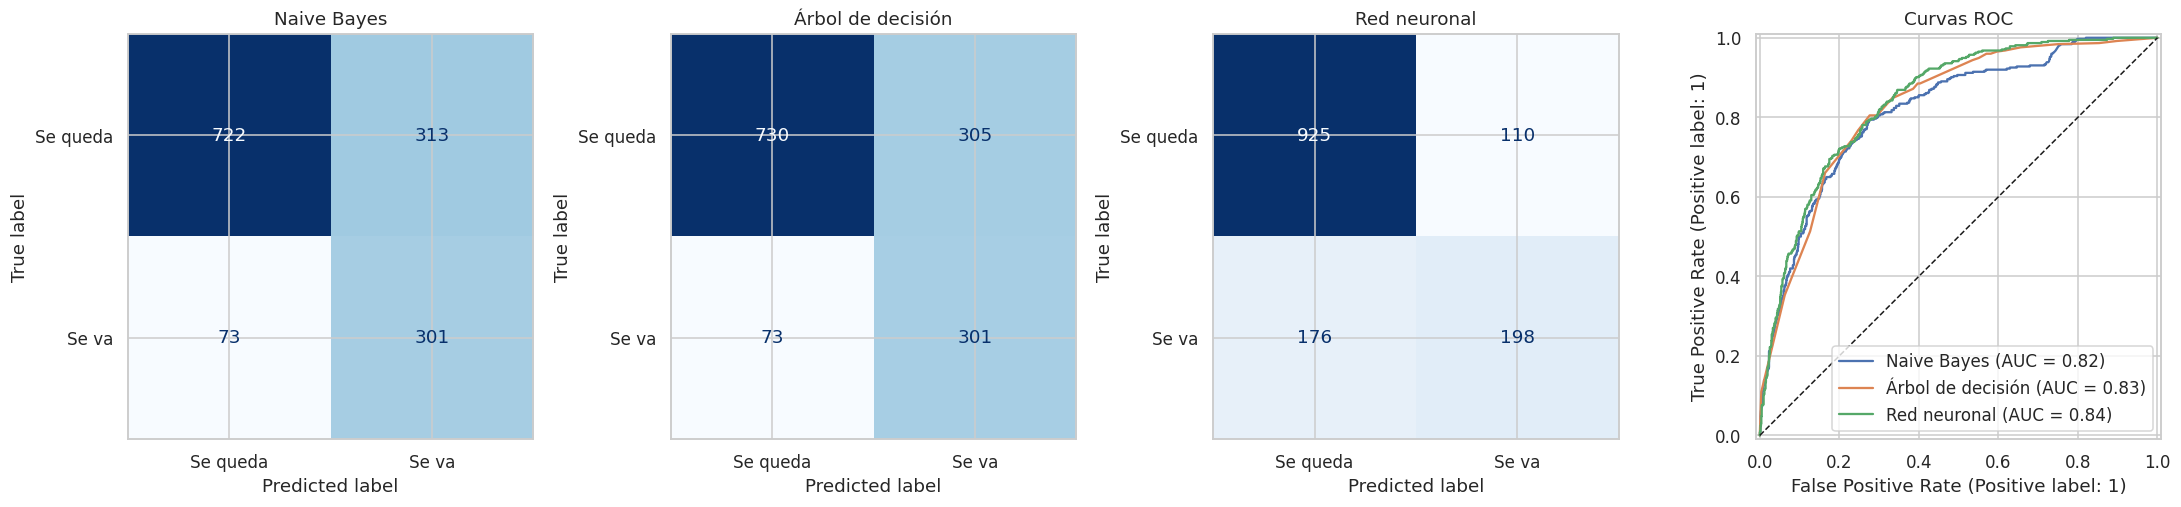

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for i, (nombre, p) in enumerate(pipes.items()):
    ConfusionMatrixDisplay.from_predictions(yte, p.predict(Xte), display_labels=["Se queda", "Se va"],
                                            cmap="Blues", colorbar=False, ax=ax[i])
    ax[i].set_title(nombre)
    RocCurveDisplay.from_estimator(p, Xte, yte, name=nombre, ax=ax[3])
ax[3].plot([0, 1], [0, 1], "k--", lw=1); ax[3].set_title("Curvas ROC")
plt.tight_layout(); plt.show()

### 6.2 ¿Qué mira el árbol de decisión?

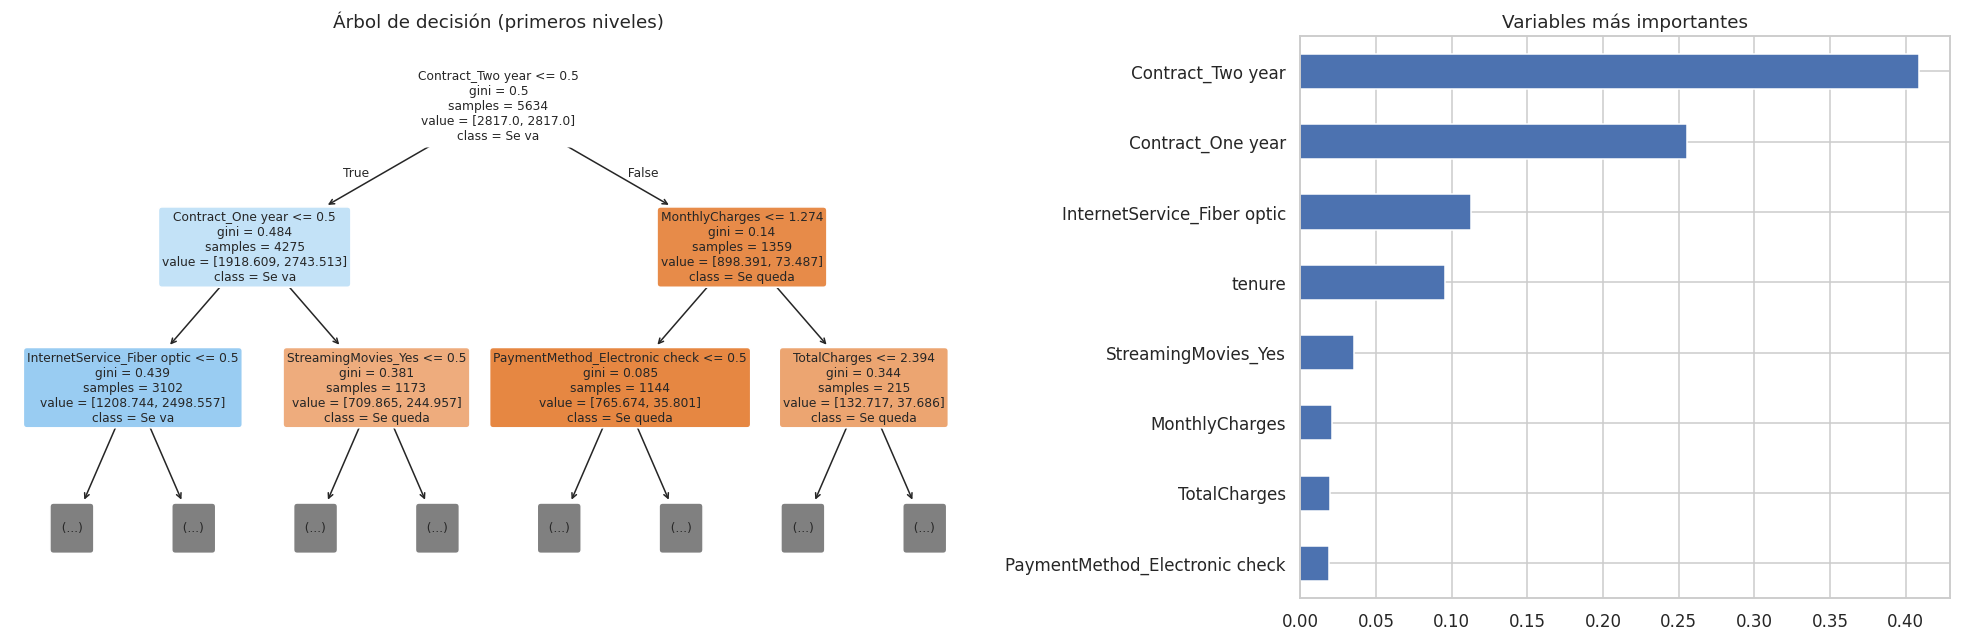

In [ ]:
arbol = pipes["Árbol de decisión"]
nombres = [n.split("__")[1] for n in arbol.named_steps["pre"].get_feature_names_out()]

fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.5, 1]})
plot_tree(arbol.named_steps["m"], max_depth=2, feature_names=nombres, class_names=["Se queda", "Se va"],
          filled=True, rounded=True, fontsize=8, ax=ax[0])
ax[0].set_title("Árbol de decisión (primeros niveles)")
imp = pd.Series(arbol.named_steps["m"].feature_importances_, index=nombres).sort_values().tail(8)
imp.plot.barh(ax=ax[1], color="#4C72B0"); ax[1].set_title("Variables más importantes")
plt.tight_layout(); plt.show()

### 6.3 Del modelo a la plata: ¿a quién llamamos primero?

Modelo usado: Red neuronal
Cancelación normal en la muestra de prueba      : 26.5%
Cancelación dentro del 20 % con más riesgo      : 65.8%
Cancelaciones encontradas con solo ese 20 %     : 49.5%
Ingreso mensual perdido (muestra de prueba)     : USD 27,215
... de ese ingreso, está en ese 20 %            : USD 14,287 (52.5%)


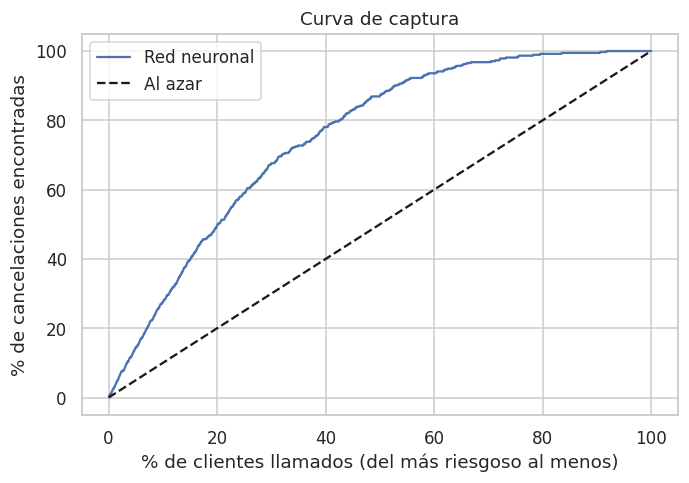

In [ ]:
mejor = resultados["AUC (prueba)"].idxmax()          # el modelo con mejor AUC
print("Modelo usado:", mejor)
t = Xte.copy(); t["prob"] = pipes[mejor].predict_proba(Xte)[:, 1]; t["real"] = yte.values
t = t.sort_values("prob", ascending=False)
top = t.head(int(0.20 * len(t)))                       # el 20 % con más riesgo

print(f"Cancelación normal en la muestra de prueba      : {t.real.mean():.1%}")
print(f"Cancelación dentro del 20 % con más riesgo      : {top.real.mean():.1%}")
print(f"Cancelaciones encontradas con solo ese 20 %     : {top.real.sum()/t.real.sum():.1%}")
perdido = (t.real * t.MonthlyCharges).sum(); perdido_top = (top.real * top.MonthlyCharges).sum()
print(f"Ingreso mensual perdido (muestra de prueba)     : USD {perdido:,.0f}")
print(f"... de ese ingreso, está en ese 20 %            : USD {perdido_top:,.0f} ({perdido_top/perdido:.1%})")

cap = t.real.cumsum() / t.real.sum()
plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, len(t)+1) / len(t) * 100, cap.values * 100, label=mejor)
plt.plot([0, 100], [0, 100], "k--", label="Al azar")
plt.xlabel("% de clientes llamados (del más riesgoso al menos)"); plt.ylabel("% de cancelaciones encontradas")
plt.title("Curva de captura"); plt.legend(); plt.show()

### 6.4 Pronóstico del cobro mensual (`MonthlyCharges`): Árbol de decisión y Red neuronal

,MAE (USD),RMSE (USD),R²
Modelo,,,
Árbol de decisión,1.703,2.414,0.994
Red neuronal,1.057,1.376,0.998


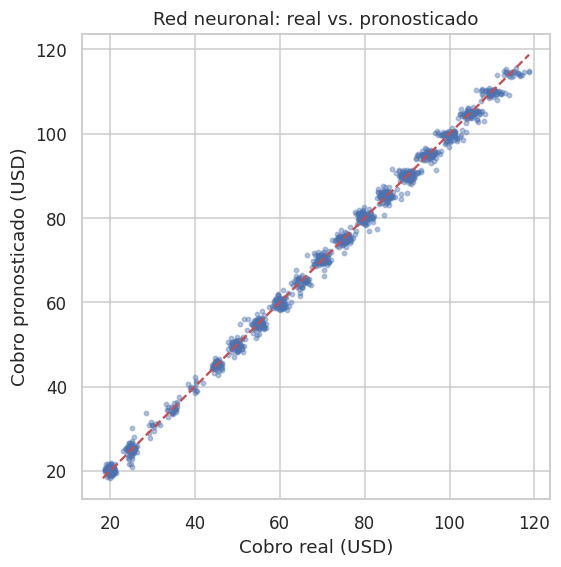

Cobro mensual promedio por tipo de internet (USD):
InternetService
DSL            58.1
Fiber optic    91.5
No             21.1
Name: MonthlyCharges, dtype: float64


In [ ]:
Xr = df.drop(columns=["Churn", "ChurnBin", "MonthlyCharges", "TotalCharges"]); yr = df["MonthlyCharges"]
catr = Xr.select_dtypes("object").columns.tolist(); numr = [c for c in Xr.columns if c not in catr]
pre_r = ColumnTransformer([("c", OneHotEncoder(drop="first"), catr), ("n", StandardScaler(), numr)])
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=SEED)

reg = {"Árbol de decisión": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=SEED),
       "Red neuronal": TransformedTargetRegressor(
           MLPRegressor(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=1000, random_state=SEED),
           transformer=StandardScaler())}
filas, pipes_r = [], {}
for nombre, m in reg.items():
    p = Pipeline([("pre", pre_r), ("m", m)]).fit(Xr_tr, yr_tr); pred = p.predict(Xr_te); pipes_r[nombre] = p
    filas.append({"Modelo": nombre, "MAE (USD)": mean_absolute_error(yr_te, pred),
                  "RMSE (USD)": np.sqrt(mean_squared_error(yr_te, pred)), "R²": r2_score(yr_te, pred)})
display(pd.DataFrame(filas).set_index("Modelo").round(3))

pred = pipes_r["Red neuronal"].predict(Xr_te)
plt.figure(figsize=(5.5, 5.5)); plt.scatter(yr_te, pred, s=8, alpha=.4)
plt.plot([yr.min(), yr.max()], [yr.min(), yr.max()], "r--")
plt.xlabel("Cobro real (USD)"); plt.ylabel("Cobro pronosticado (USD)"); plt.title("Red neuronal: real vs. pronosticado")
plt.show()

print("Cobro mensual promedio por tipo de internet (USD):")
print(df.groupby("InternetService").MonthlyCharges.mean().round(1))

### 6.5 Grupos de clientes con K-Means

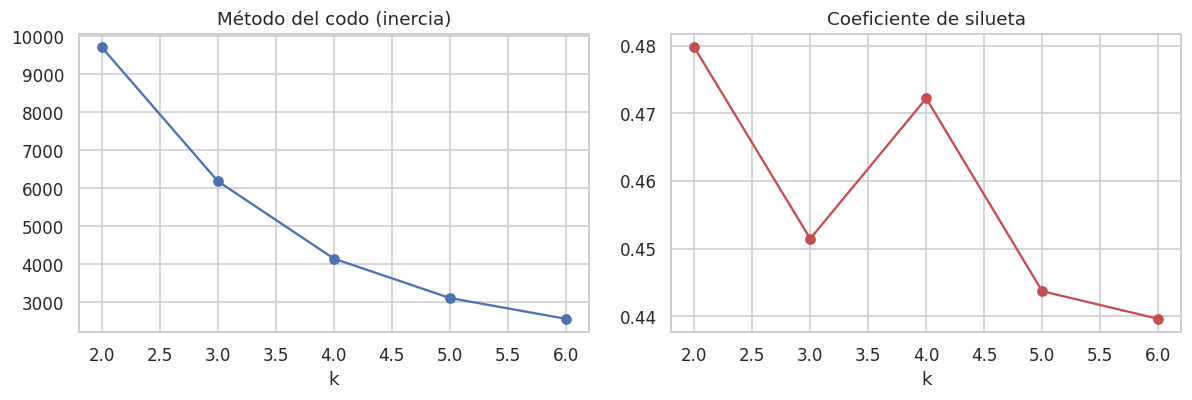

{2: np.float64(0.48), 3: np.float64(0.451), 4: np.float64(0.472), 5: np.float64(0.444), 6: np.float64(0.44)}


In [ ]:
Z = StandardScaler().fit_transform(df[["tenure", "MonthlyCharges", "TotalCharges"]])
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)) for k in range(2, 7)}
inercia = {k: KMeans(k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in range(2, 7)}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(inercia), list(inercia.values()), "o-"); ax[0].set_title("Método del codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(list(sil), list(sil.values()), "o-r"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in sil.items()})

Elegimos **k = 3**. Con k = 2 la silueta es un poco más alta (0,480), pero solo separa a los que pagan poco de los que pagan mucho. Con k = 3 la silueta es 0,451 y también se separan los clientes nuevos de los antiguos, que es lo que más importa para retener clientes.

,clientes,antiguedad,cobro_mensual,total_facturado,cancelacion,ingreso_mensual_perdido,% del ingreso perdido
cluster,,,,,,,
Básicos de bajo gasto,2154,29.50,26.57,809.42,0.12,7771.60,5.59
Leales premium,2200,58.56,89.70,5246.13,0.15,32351.95,23.25
Nuevos de alto gasto,2689,13.25,74.95,1030.57,0.47,99007.30,71.16



Composición de contrato por segmento:


Contract,Month-to-month,One year,Two year
segmento,,,
Básicos de bajo gasto,0.44,0.24,0.33
Leales premium,0.26,0.31,0.43
Nuevos de alto gasto,0.87,0.11,0.02


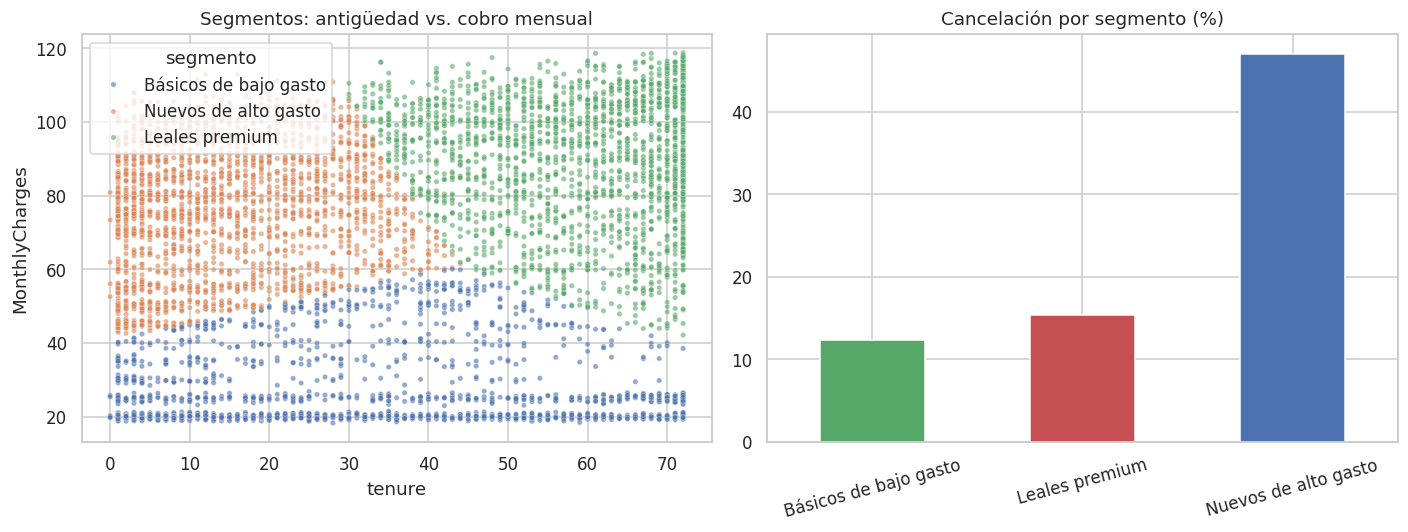

In [ ]:
km = KMeans(3, n_init=10, random_state=SEED).fit(Z)
df["cluster"] = km.labels_
perfil = df.groupby("cluster").agg(clientes=("cluster", "size"), antiguedad=("tenure", "mean"),
                                   cobro_mensual=("MonthlyCharges", "mean"), total_facturado=("TotalCharges", "mean"),
                                   cancelacion=("ChurnBin", "mean"))
# Nombres automáticos según el perfil (así no dependen del número que asigne K-Means)
nombres_cl = {}
nombres_cl[perfil.cobro_mensual.idxmin()] = "Básicos de bajo gasto"
nombres_cl[perfil.antiguedad.idxmax()] = "Leales premium"
nombres_cl[[c for c in perfil.index if c not in nombres_cl][0]] = "Nuevos de alto gasto"
df["segmento"] = df["cluster"].map(nombres_cl)
perfil.index = perfil.index.map(nombres_cl)
perfil["ingreso_mensual_perdido"] = df.groupby("segmento").apply(lambda g: (g.ChurnBin * g.MonthlyCharges).sum())
perfil["% del ingreso perdido"] = perfil.ingreso_mensual_perdido / perfil.ingreso_mensual_perdido.sum() * 100
display(perfil.round(2))

print("\nComposición de contrato por segmento:")
display(pd.crosstab(df.segmento, df.Contract, normalize="index").round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="segmento", s=12, alpha=.6, ax=ax[0])
ax[0].set_title("Segmentos: antigüedad vs. cobro mensual")
(perfil.cancelacion * 100).plot.bar(ax=ax[1], color=["#55A868", "#C44E52", "#4C72B0"]); ax[1].set_title("Cancelación por segmento (%)")
ax[1].tick_params(axis="x", rotation=15); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 7. Discusión de los resultados

**1. El contrato es lo que más pesa.** Con contrato mensual cancela el 42,7 % de los clientes, con contrato de un año el 11,3 % y con contrato de dos años solo el 2,8 %. El árbol de decisión lo confirma: su primera pregunta es si el cliente tiene contrato de dos años, y esa variable es la más importante del árbol (0,41), seguida del contrato de un año (0,26). Después vienen la fibra óptica (0,11) y la antigüedad (0,10). Eso sí, no sabemos si el contrato largo hace que el cliente se quede o si los clientes contentos son los que firman contratos largos. Los modelos muestran que hay una relación, pero no prueban la causa. Aun así, la empresa puede probar descuentos a cambio de contratos largos y ver si funciona.

**2. Los primeros meses son los más peligrosos.** El 62 % de los clientes con un solo mes de antigüedad cancela. A los 12 meses baja a 32,5 %, a los 24 meses a 24,5 %, a los 48 meses a 14,1 % y a los 72 meses a 1,7 %. Casi todo el riesgo está al principio. Pensamos que muchos se van porque la experiencia inicial no fue buena, por ejemplo por problemas con la instalación o por una primera factura distinta a lo que esperaban. Esto es una idea nuestra, porque la base no tiene datos para confirmarlo.

**3. La fibra óptica y el cheque electrónico.** Cancela el 41,9 % de los clientes con fibra óptica, frente al 19,0 % de DSL y el 7,4 % de los que no tienen internet. Nos pareció raro, porque la fibra es el servicio más caro (USD 91,5 al mes en promedio, contra USD 58,1 de DSL) y debería ser el mejor. Puede ser por el precio, por fallas del servicio o porque otras empresas ofrecen algo mejor, pero con estos datos no podemos saberlo. La empresa debería preguntarles a esos clientes por qué se van. Con el cheque electrónico pasa algo parecido: cancela el 45,3 %, mientras que con tarjeta automática cancela el 15,2 % y con transferencia automática el 16,7 %. Cuando el pago es automático, el cliente no tiene que decidir cada mes si sigue o no.

**4. Comparación de los tres modelos de clasificación.** Los tres modelos sirven, pero cada uno tiene algo distinto. La **Red neuronal** tuvo el mejor AUC (0,843 en la prueba y 0,840 en la validación cruzada) y la mejor exactitud (79,7 %) y precisión (64,3 %). Sin embargo, su recall fue de solo 52,9 %, o sea que se le pasan casi la mitad de los clientes que sí se van. El **Árbol de decisión** tuvo un AUC de 0,829 y un recall de 80,5 %, y el **Naive Bayes** un AUC de 0,817 y también un recall de 80,5 %. Estos dos encuentran muchos más clientes que se van, pero se equivocan más al marcar clientes que en realidad se quedan (precisión de 49,7 % y 49,0 %). Entonces, si la empresa quiere no dejar pasar a nadie, le sirven más el árbol o el Naive Bayes. Si prefiere equivocarse menos, le sirve más la red. Además, el árbol se puede explicar fácil, porque se ve cada pregunta que hace, mientras que la red neuronal es una caja negra. El Naive Bayes es el más simple, pero supone que las variables no dependen una de otra, y eso no es del todo cierto en esta base (por ejemplo, quien tiene fibra suele tener más servicios extra). Aun así, no le fue tan mal.

**5. Cuánta plata se puede salvar.** Usamos la red neuronal (la de mejor AUC) para ordenar a los clientes de la muestra de prueba del más riesgoso al menos riesgoso, y miramos solo el 20 % de arriba. De ellos, el 65,8 % sí canceló, que es 2,5 veces más que el 26,5 % normal. Con ese 20 % encontramos el 49,5 % de todas las cancelaciones y el 52,5 % del ingreso mensual que se perdió (USD 14.287 de USD 27.215). Entonces, enfocándose en una quinta parte de los clientes, la empresa llega a más de la mitad del problema. Para nosotros esta es la parte más útil del proyecto, porque convierte un modelo en una decisión concreta: a quién llamar primero y cuánta plata se puede proteger con esa llamada.

**6. Pronóstico del cobro mensual.** La red neuronal tuvo un R² de 0,998 y un error promedio de USD 1,06. El árbol de decisión tuvo un R² de 0,994 y un error de USD 1,70. Los dos son resultados casi demasiado buenos y, al revisarlos, entendimos por qué: el cobro mensual es básicamente la suma de los servicios que tiene el cliente, como una lista de precios. Los modelos solo aprendieron esa lista. Entonces no adivinan nada difícil, pero sirven para calcular cuánto subiría el ingreso si se le vende un servicio más a un cliente, o para encontrar facturas raras. La red neuronal quedó mejor porque puede sumar muchos servicios a la vez, y el árbol tiene que cortar el cobro en escalones. Además, como la base es una foto de un solo momento, no se puede hacer un pronóstico en el tiempo.

**7. Los grupos de clientes.** Con K-Means salieron tres grupos. Los **Nuevos de alto gasto** son 2.689 clientes con 13 meses en promedio, pagan USD 75 al mes, el 87 % tiene contrato mensual y cancela el 47 %. Este grupo tiene el 71 % del ingreso mensual perdido. Los **Leales premium** son 2.200 clientes con 59 meses en promedio y USD 90 al mes. Cancelan poco (15 %), pero como pagan tanto, perderlos cuesta mucho y representan el 23 % del ingreso perdido. Los **Básicos de bajo gasto** son 2.154 clientes que pagan USD 27 al mes, casi todos sin internet, cancelan 12 % y solo tienen el 5,6 % del ingreso perdido. Con ellos la idea es venderles más servicios.

**8. Todo junto.** Los análisis cuentan la misma historia. El cliente que más le cuesta perder a la empresa es el que llegó hace poco, paga bastante, tiene contrato mensual y no paga de forma automática. Esto no es casualidad. Los modelos de clasificación lo marcan como riesgoso, el grupo de K-Means lo muestra con la mayor pérdida y el pronóstico explica por qué paga tanto: seguramente tiene fibra óptica y servicios de streaming. Por eso creemos que la empresa debería empezar por este tipo de cliente antes que por cualquier otro.

## 8. Limitaciones y retos

- Los datos son de un solo momento. No hay fechas de cancelación, así que no se puede ver cómo cambia todo mes a mes.
- Faltan datos que seguro influyen, como quejas, fallas del servicio o precios de la competencia.
- Es una base de ejemplo de IBM. No sabemos de qué empresa ni de qué país es, así que sirve para practicar el método y no para aplicarlo tal cual en otra empresa.
- Solo el 26,5 % cancela y no ajustamos los modelos a fondo (por ejemplo, la forma de la red neuronal o la profundidad del árbol). Con otros valores los resultados podrían cambiar un poco.
- La red neuronal es difícil de explicar a un gerente.
- El R² tan alto del pronóstico se explica porque el cobro depende de los servicios, no porque el problema fuera fácil.
- En una empresa real hay que revisar el modelo cada cierto tiempo y conectarlo con el equipo que llama a los clientes.

## 9. Ética y buenas prácticas

- **Datos personales.** En Colombia aplica la Ley 1581 de 2012 (Habeas Data). Hay que usar los datos solo para lo que el cliente autorizó y cuidarlos. En esta base no hay nombres y no usamos el código del cliente.
- **Discriminación.** La base tiene género y edad. No deberían usarse para decidir quién recibe una oferta, porque sería injusto.
- **Uso de las predicciones.** Que el modelo diga que un cliente es riesgoso no es una verdad, es una probabilidad. Debe usarse para dar mejor servicio y no para perjudicar al cliente.
- **Justicia con todos.** Si solo se dan descuentos a los que amenazan con irse, los clientes fieles quedan en desventaja.
- **Explicar las decisiones.** Es mejor poder decir por qué se marcó a un cliente como riesgoso. Por eso el árbol de decisión es útil.

## 10. Conclusiones

1. La cancelación se relaciona sobre todo con el **contrato**, la **antigüedad**, el **tipo de internet** y la **forma de pago**. Con contrato mensual cancela el 42,7 % y con contrato de dos años el 2,8 %.
2. Los tres modelos de clasificación funcionan. La **Red neuronal** tiene el mejor AUC (0,843), pero el **Árbol de decisión** y el **Naive Bayes** encuentran más clientes que se van (recall de 80,5 %).
3. Llamando solo al 20 % de clientes con más riesgo, la empresa encuentra el 49,5 % de las cancelaciones y el 52,5 % del ingreso mensual en riesgo.
4. El cobro mensual se pronostica casi sin error (R² de 0,998 con la red neuronal) porque depende de los servicios.
5. El grupo de **clientes nuevos de alto gasto** tiene el 71 % del ingreso mensual perdido.
6. Hay limitaciones, y hay que cuidar los datos personales de los clientes.

## 11. Recomendaciones

1. **Cuidar a los clientes nuevos** con un programa de bienvenida en los primeros 90 días (llamada de seguimiento y revisión de la primera factura).
2. **Ofrecer contratos más largos** con un descuento o beneficio, y comparar con un grupo de control para ver si ayuda de verdad.
3. **Promover el pago automático** con un pequeño beneficio.
4. **Revisar el servicio de fibra óptica** con encuestas a los que se van.
5. **Usar el modelo cada mes** para hacer una lista de los clientes con más riesgo y llamar primero al 20 % de arriba.
6. **Atender bien a los Leales premium**, porque perder uno cuesta mucho.
7. **Venderles más servicios a los Básicos de bajo gasto.**
8. **No usar género ni edad** para decidir ofertas.

## 12. Bibliografía

- IBM. (s. f.). *Telco Customer Churn* [base de datos]. Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- IBM. (s. f.). *Telco customer churn on ICP4D* [repositorio]. GitHub: https://github.com/IBM/telco-customer-churn-on-icp4d
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning with Applications in Python*. Springer.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65.
- Congreso de la República de Colombia. (2012). *Ley Estatutaria 1581 de 2012*.